# 05 - Final evaluation on the test year

**Goal:** evaluate the chosen model and the baseline once on the test year (2017), and report the late-check years (2018-2019) separately.

**Fixed in advance (nothing is changed after seeing these results)**
- Models: LightGBM with default settings (the chosen model) and logistic regression (baseline), both refit on 2003-2016.
- Decision thresholds from the validation year: logistic regression 0.62, LightGBM 0.66.
- Metrics: ROC-AUC, PR-AUC, precision, recall, F1, MCC and Recall@20%Effort (per line). Per-project results only for projects with at least 200 test commits.
- The thresholds were tuned for a model trained on 2003-2015, and are applied here to models that also saw 2016, so the share of flagged commits may differ slightly from the validation value (about 32%).

In [4]:
import sys
sys.path.append("..")

import json
import pandas as pd
from sklearn.metrics import average_precision_score, roc_auc_score

from src.data.split import load_data, time_split, FEATURES, LABEL
from src.evaluation.metrics import evaluate, recall_at_effort
from src.models.builders import make_logistic_regression, make_lightgbm

df = load_data()
train, validation, test, late = time_split(df)

with open("../results/04_lightgbm_params.json") as f:
    lgbm_params = json.load(f)

THRESHOLDS = {"logistic regression": 0.62, "lightgbm": 0.66}

dev = pd.concat([train, validation])
final = {
    "logistic regression": make_logistic_regression(),
    "lightgbm": make_lightgbm(**lgbm_params),
}
for model in final.values():
    model.fit(dev[FEATURES], dev[LABEL])

## 1. One evaluation on the test year and the late check

**Goal:** score both models on 2017 (the test) and on 2018-2019, using the fixed thresholds. `flagged share` is the share of commits predicted as risky.

In [5]:
def score(part):
    effort = (part["la"] + part["ld"]).to_numpy()
    out = {}
    for name, model in final.items():
        p = model.predict_proba(part[FEATURES])[:, 1]
        row = evaluate(part[LABEL], p, threshold=THRESHOLDS[name])
        row["flagged share"] = (p >= THRESHOLDS[name]).mean()
        row["Recall@20%Effort (per line)"] = recall_at_effort(part[LABEL], p / (effort + 1), effort, 0.2)
        out[name] = row
    return pd.DataFrame(out)

final_results = pd.concat({"test 2017": score(test), "late check 2018-2019": score(late)})
final_results.round(4).to_csv("../results/05_final_test.csv")
final_results.round(3)

logistic regression  \
test 2017            ROC-AUC                                    0.800   
                     PR-AUC                                     0.609   
                     precision                                  0.539   
                     recall                                     0.649   
                     F1                                         0.589   
                     MCC                                        0.419   
                     bug share                                  0.272   
                     flagged share                              0.328   
                     Recall@20%Effort (per line)                0.583   
late check 2018-2019 ROC-AUC                                    0.794   
                     PR-AUC                                     0.413   
                     precision                                  0.334   
                     recall                                     0.680   
                     F1                                         0.448   
                     MCC                                        0.338   
                     bug share                                  0.153   
                     flagged share                              0.311   
                     Recall@20%Effort (per line)                0.532   

                                                  lightgbm  
test 2017            ROC-AUC                         0.818  
                     PR-AUC                          0.637  
                     precision                       0.578  
                     recall                          0.639  
                     F1                              0.607  
                     MCC                             0.451  
                     bug share                       0.272  
                     flagged share                   0.301  
                     Recall@20%Effort (per line)     0.600  
late check 2018-2019 ROC-AUC                         0.801  
                     PR-AUC                          0.422  
                     precision                       0.350  
                     recall                          0.649  
                     F1                              0.455  
                     MCC                             0.345  
                     bug share                       0.153  
                     flagged share                   0.283  
                     Recall@20%Effort (per line)     0.547

## 2. Results by project (test year)

**Goal:** check whether the result holds across projects. Only projects with at least 200 test commits are shown, with the three Hadoop repository names merged.The `bug share` bar is the PR-AUC of a random model.

In [6]:
test = test.assign(group=test["project"].replace({
    "apache/hadoop": "hadoop", "apache/hadoop-hdfs": "hadoop", "apache/hadoop-mapreduce": "hadoop"}))
counts = test["group"].value_counts()
big = counts[counts >= 200].index

rows = []
for g in big:
    part = test[test["group"] == g]
    row = {"project": g, "commits": len(part), "bug share": part[LABEL].mean()}
    for name, model in final.items():
        p = model.predict_proba(part[FEATURES])[:, 1]
        row[f"{name} PR-AUC"] = average_precision_score(part[LABEL], p)
        row[f"{name} ROC-AUC"] = roc_auc_score(part[LABEL], p)
    rows.append(row)
by_project = pd.DataFrame(rows).set_index("project").sort_values("commits", ascending=False)
by_project.round(4).to_csv("../results/05_test_by_project.csv")
by_project.round(3)

,commits,bug share,logistic regression PR-AUC,logistic regression ROC-AUC,lightgbm PR-AUC,lightgbm ROC-AUC
project,,,,,,
apache/camel,2130,0.091,0.300,0.761,0.246,0.751
hadoop,1666,0.092,0.195,0.719,0.163,0.692
apache/ignite,1657,0.289,0.749,0.858,0.725,0.852
apache/flink,1139,0.396,0.743,0.816,0.727,0.807
apache/hbase,849,0.345,0.646,0.793,0.640,0.789
apache/hive,844,0.586,0.840,0.801,0.852,0.807
apache/kafka,636,0.555,0.884,0.857,0.878,0.857
apache/groovy,416,0.087,0.232,0.730,0.303,0.739
apache/cassandra,284,0.338,0.736,0.815,0.742,0.827


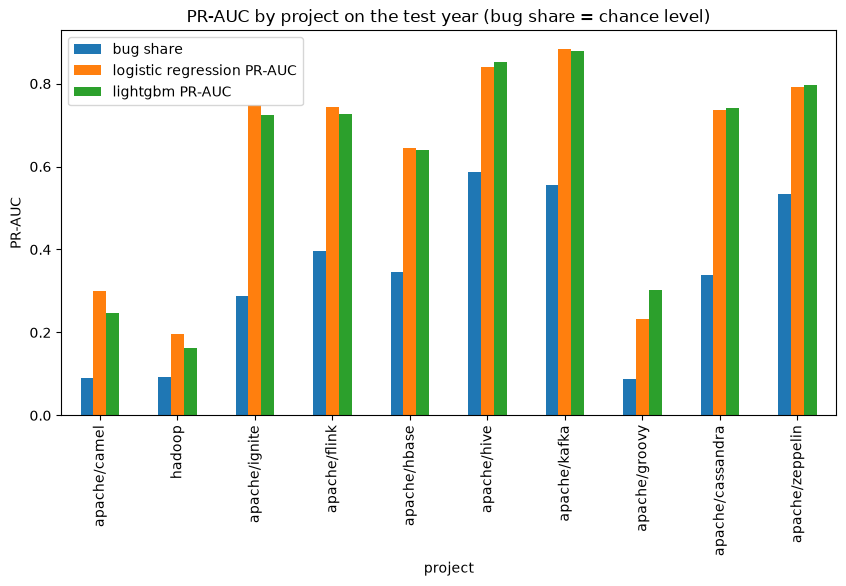

In [7]:
ax = by_project[["bug share", "logistic regression PR-AUC", "lightgbm PR-AUC"]].plot(
    kind="bar", figsize=(10, 5), title="PR-AUC by project on the test year (bug share = chance level)")
ax.set_ylabel("PR-AUC")
ax.figure.savefig("../reports/figures/05_test_by_project.png", dpi=150, bbox_inches="tight")

**Observation**
- Test year (2017): LightGBM reaches ROC-AUC 0.818, PR-AUC 0.637, MCC 0.451 and Recall@20%Effort (per line) 0.600; logistic regression reaches 0.800, 0.609, 0.419 and 0.583. These are in line with the validation year (LightGBM 0.804, 0.630, 0.435 and 0.620), so there is no sign of a performance drop on the following year. The share of flagged commits stayed close to the validation value (30.1% for LightGBM against 32.1%, and 32.8% for logistic regression against 33.6%).
- LightGBM is ahead of the baseline on the test year by 0.018 ROC-AUC, 0.028 PR-AUC and 0.032 MCC. The gain is modest, and no confidence interval was computed (one test year, about 2,770 bug-inducing commits), so we do not claim a statistically tested difference.
- Late check (2018-2019): ROC-AUC stays similar (0.801 and 0.794), but PR-AUC (0.422 and 0.413), precision (0.350 and 0.334) and MCC (0.345 and 0.338) fall because the bug share is only 15.3% instead of 27.2%, and these metrics depend on that share. Relative to the chance level, PR-AUC is not worse (0.422 / 0.153 = 2.8 times chance, against 0.637 / 0.272 = 2.3 times on the test year). The models flag 28-31% of commits while only 15% are labeled bug-inducing; some of these may be real bugs that are not linked yet (late labels), which we cannot verify. The advantage of LightGBM over logistic regression almost disappears here (+0.007 ROC-AUC, +0.009 PR-AUC).
- By project (test year, projects with at least 200 commits): both models are above chance in every project (ROC-AUC 0.69 to 0.86). The absolute PR-AUC follows each project's bug share, which ranges from about 9% (Camel, Hadoop, Groovy) to 59% (Hive). Hadoop is the weakest project (ROC-AUC 0.72 and 0.69).
- Inside single projects the two models are close: logistic regression has the higher PR-AUC in 6 of 10 projects. LightGBM is ahead mainly on the pooled data, which may mean that it uses the features to recognize project-level differences in bug share rather than ranking better within a project. This was not tested.
- Per-project numbers for the smallest projects (about 230 to 280 commits) are noisy.

**Decision:** the chosen model (LightGBM, default settings), the thresholds and the protocol stay as fixed in advance; nothing was changed after seeing the test results.

## Summary and decisions

- Final model: LightGBM (default settings, threshold 0.66), trained on 2003-2016. On the test year 2017: ROC-AUC 0.818, PR-AUC 0.637, precision 0.578, recall 0.639, F1 0.607, MCC 0.451, Recall@20%Effort (per line) 0.600; about 30% of commits are flagged.
- Baseline (logistic regression, threshold 0.62): ROC-AUC 0.800, PR-AUC 0.609, MCC 0.419.
- Complexity vs gain: the tree model is better by about 0.02-0.03 on the test year, but not within single projects and not on the late-check years, so the gain is modest.
- Late check (2018-2019): ranking quality holds (ROC-AUC about 0.80) while precision and PR-AUC drop with the lower bug share (15.3%).
- Per project: above chance everywhere; Hadoop is the weakest.

**Next:** explain the LightGBM predictions with SHAP (feature importance, single-commit explanations, stability over time).